In [46]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 20244080223

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] None
[学号] 20244080223
[机器指纹] 9262db88e33a32bc
[RUN_ID] 20244080223-9262db88e33a32bc


第一部分：半圆定律

In [47]:
import numpy as np
def wigner_density(x):
    x = np.asarray(x, dtype=float)
    val = np.where(np.abs(x) <= 2, np.sqrt(np.maximum(4 - x**2, 0)) / (2*np.pi), 0.0)
    return float(val) if np.ndim(val) == 0 else val

In [48]:
def generate_wigner(n):
    if not isinstance(n, (int, np.integer)) or isinstance(n, bool) or n <= 0:
        raise ValueError("n 必须是正整数")
    Z = np.zeros((n, n))
    # 上三角（含对角）独立抽样，方差 1/n
    iu = np.triu_indices(n)
    vals = np.random.normal(0, np.sqrt(1/n), size=len(iu[0]))
    Z[iu] = vals
    Z.T[iu] = vals   # 对称
    return Z

In [49]:
def get_spectrum(matrix):
    vals = np.linalg.eigvalsh(np.asarray(matrix))  # 对称矩阵用 eigvalsh 更快更稳
    return np.sort(vals)

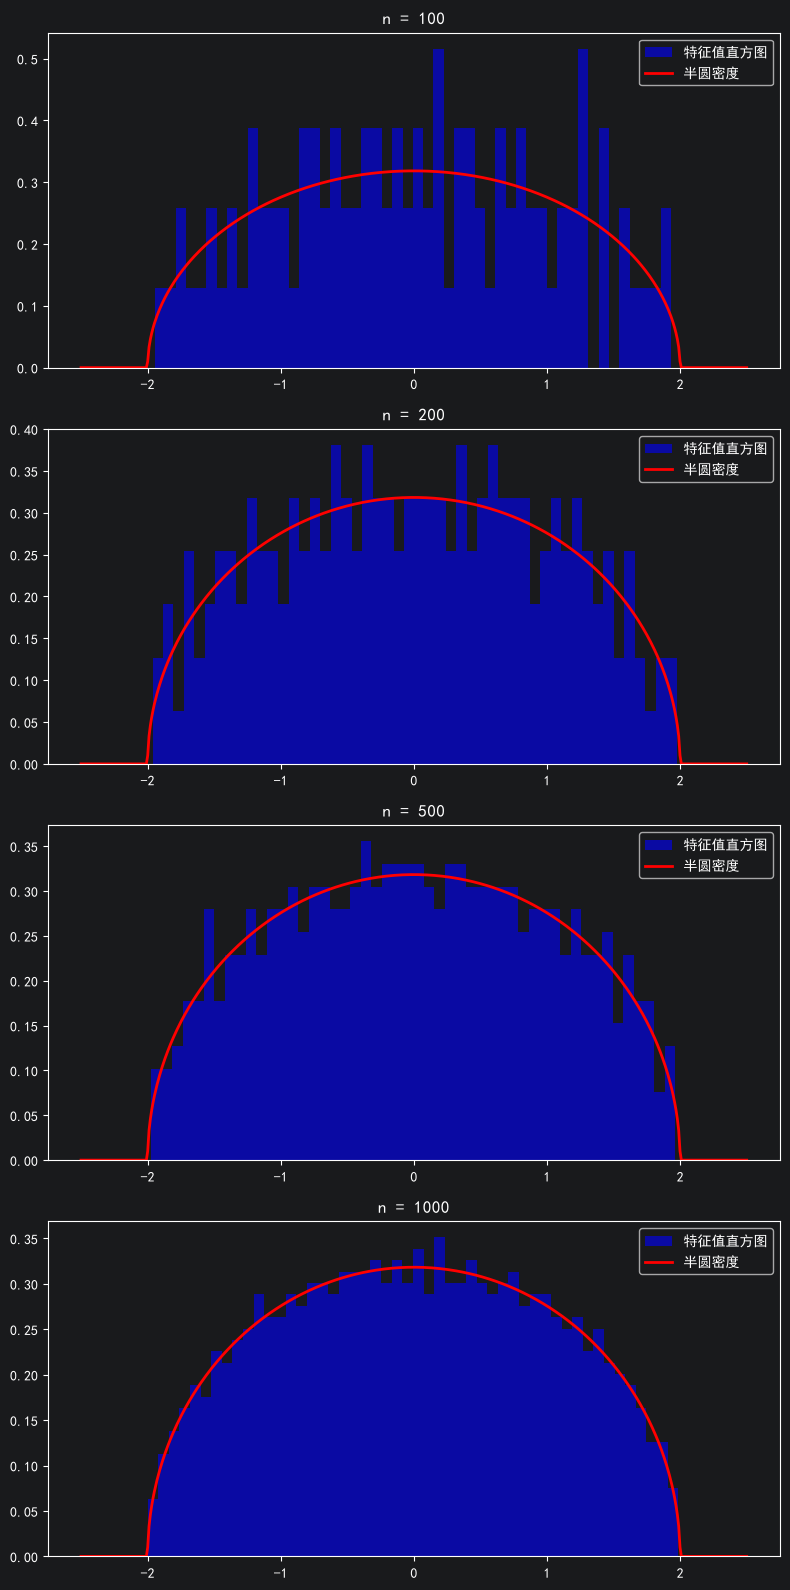

In [50]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
ns = [100, 200, 500, 1000]
fig, axes = plt.subplots(4, 1, figsize=(8, 16))
for ax, n in zip(axes, ns):
    Z = generate_wigner(n)
    ev = get_spectrum(Z)
    ax.hist(ev, bins=50, density=True, color="blue", alpha=0.6, label="特征值直方图")
    xs = np.linspace(-2.5, 2.5, 500)
    ax.plot(xs, [wigner_density(x) for x in xs], "r-", lw=2, label="半圆密度")
    ax.set_title(f"n = {n}")
    ax.legend()
plt.tight_layout()
plt.show()

第二部分：Conway 生命游戏

In [51]:
def is_valid_board(board):
    # 1. 检查是否为 ndarray
    if not isinstance(board, np.ndarray):
        return False
    # 2. 检查是否二维
    if board.ndim != 2:
        return False
    # 3. 检查元素是否只包含 0 和 1
    # np.isin 会返回一个和 board 同形状的布尔矩阵，.all() 检查是否全为 True
    if not np.isin(board, [0, 1]).all():
        return False

    # 题目要求返回 Python 的布尔值（原生 True/False），必须用 bool() 转换
    return bool(True)

In [52]:
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("无效棋盘")
    b = board.astype(int)

    # 巧妙使用 np.roll 来实现“环绕边界”并计算邻居的总和
    # (i, j) 分别是行和列的偏移量，排除 (0,0) 也就是细胞自己
    neighbors = np.sum(
        [np.roll(np.roll(b, i, axis=0), j, axis=1)
         for i in (-1, 0, 1) for j in (-1, 0, 1)
         if not (i == 0 and j == 0)],
        axis=0
    )

    new_board = np.zeros_like(b)

    # 规则 1 & 2：原来活着的细胞（b == 1），邻居是 2 或 3 时继续存活
    # 规则 3：邻居大于 3 或者小于 2 的，在上面条件里没包含，保持 0（死亡）
    new_board[(b == 1) & ((neighbors == 2) | (neighbors == 3))] = 1

    # 规则 4：原来死着的细胞（b == 0），且邻居刚好是 3 时复活
    new_board[(b == 0) & (neighbors == 3)] = 1

    # 规则 5：其他死细胞保持死亡（初始化已经是 0 了，不用管）

    return new_board

In [53]:
def draw_gol_board(board):
    # 使用 gray_r 颜色映射：1（活）映射为黑色，0（死）映射为白色
    plt.imshow(board, cmap="gray_r", interpolation="nearest")

    # 隐藏坐标轴的刻度和标签
    plt.xticks([]); plt.yticks([])

    # 关闭网格线
    plt.grid(False)

    # 显示图像
    plt.show()

第三部分：pandas 处理 iris

In [55]:
import pandas as pd
df = pd.read_csv("Iris.csv")
print("形状:", df.shape)
print(df.dtypes)
print(list(df.columns))
print("种类数:", df["Species"].nunique(), df["Species"].unique().tolist())

形状: (150, 6)
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object
['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
种类数: 3 ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']


In [56]:
print("修改前:\n", df.loc[[34, 37]])

# 按列名赋值，避免列顺序问题
df.loc[34, ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm", "Species"]] = \
    [4.9, 3.1, 1.5, 0.2, "Iris-setosa"]

df.loc[37, ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm", "Species"]] = \
    [4.9, 3.6, 1.4, 0.1, "Iris-setosa"]

print("\n修改后:\n", df.loc[[34, 37]])

修改前:
     Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
34  35            4.9           3.1            1.5           0.1  Iris-setosa
37  38            4.9           3.1            1.5           0.1  Iris-setosa

修改后:
     Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
34  35            4.9           3.1            1.5           0.2  Iris-setosa
37  38            4.9           3.6            1.4           0.1  Iris-setosa


In [57]:
df["Petal.Ratio"] = df["PetalLengthCm"] / df["PetalWidthCm"]
df["Sepal.Ratio"] = df["SepalLengthCm"] / df["SepalWidthCm"]

print(df[["Petal.Ratio", "Sepal.Ratio"]].head())
print("\n是否有缺失/无穷:", df[["Petal.Ratio", "Sepal.Ratio"]].isna().any().any())

   Petal.Ratio  Sepal.Ratio
0          7.0     1.457143
1          7.0     1.633333
2          6.5     1.468750
3          7.5     1.483871
4          7.0     1.388889

是否有缺失/无穷: False


In [58]:
df.to_csv("iris_corrected.csv", index=False)
print("已保存 iris_corrected.csv，形状:", df.shape)

已保存 iris_corrected.csv，形状: (150, 8)


In [61]:
agg = df.groupby("Species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
agg.columns = ["_".join(col) for col in agg.columns]
print(agg.T)

Species             Iris-setosa  Iris-versicolor  Iris-virginica
Petal.Ratio_mean       6.908000         3.242837        2.780662
Petal.Ratio_median     7.000000         3.240385        2.666667
Petal.Ratio_min        2.666667         2.666667        2.125000
Petal.Ratio_max       15.000000         4.100000        4.000000
Petal.Ratio_std        2.854545         0.312456        0.407367
Sepal.Ratio_mean       1.470188         2.160402        2.230453
Sepal.Ratio_median     1.463063         2.161290        2.169540
Sepal.Ratio_min        1.268293         1.764706        1.823529
Sepal.Ratio_max        1.956522         2.818182        2.961538
Sepal.Ratio_std        0.118750         0.228658        0.246992
